# Import necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

import warnings
warnings.filterwarnings('ignore')

# Data Preprocessing

In [2]:

df =pd.read_excel(
    r"E:\Python-Data-Analysis-Projects-Package\Python Data Analysis Projects Package\Project 7\employee_performance_attrition.csv.xlsx"
)



imputer = SimpleImputer(strategy='most_frequent')
df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)


df['Attrition'] = pd.to_numeric(df['Attrition'], errors='coerce')


df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})
df['Department'] = df['Department'].map({'HR': 0, 'IT': 1, 'Sales': 2, 'Marketing': 3, 'Finance': 4})
df['JobRole'] = df['JobRole'].map({'Manager': 0, 'Developer': 1, 'Analyst': 2, 'Executive': 3})
df['OverTime'] = df['OverTime'].map({'No': 0, 'Yes': 1})

scaler = StandardScaler()
df[['Age', 'Salary', 'YearsAtCompany']] = scaler.fit_transform(df[['Age', 'Salary', 'YearsAtCompany']])

# Exploratory Data Analysis (EDA)

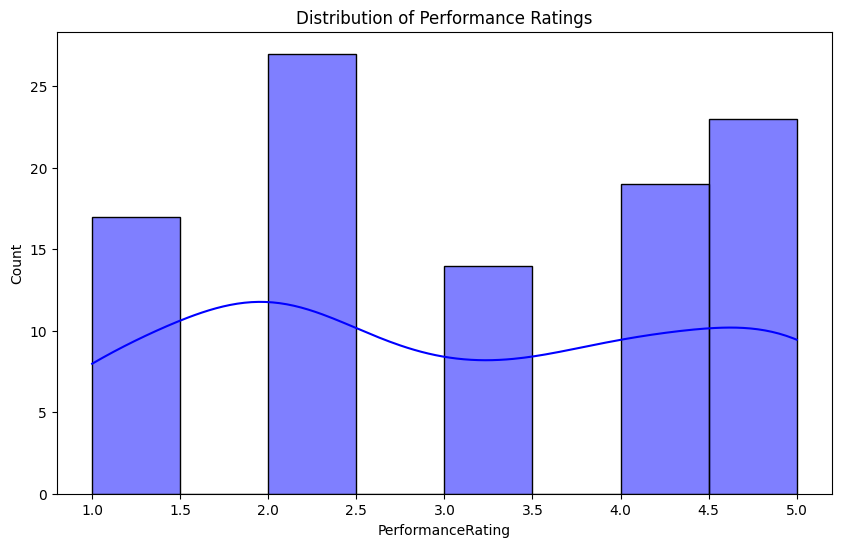

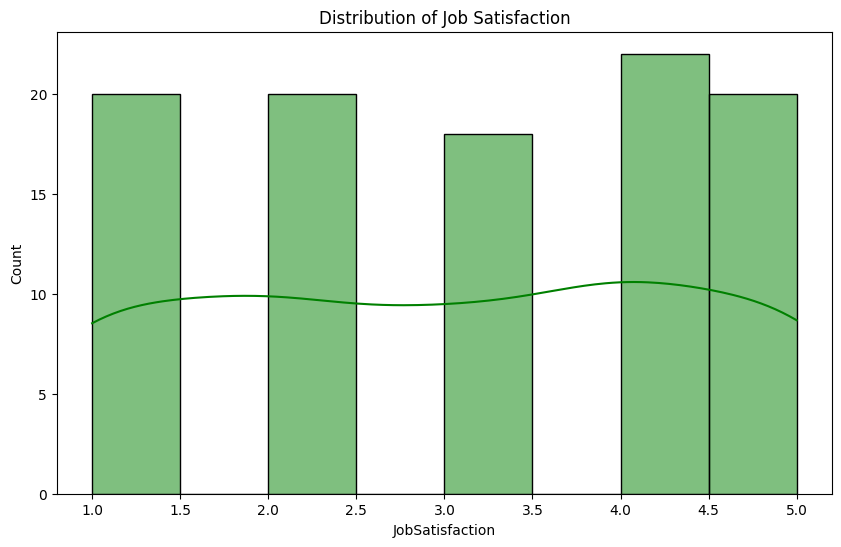

In [3]:

plt.figure(figsize=(10, 6))
sns.histplot(df['PerformanceRating'], kde=True, color='blue')
plt.title('Distribution of Performance Ratings')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(df['JobSatisfaction'], kde=True, color='green')
plt.title('Distribution of Job Satisfaction')
plt.show()

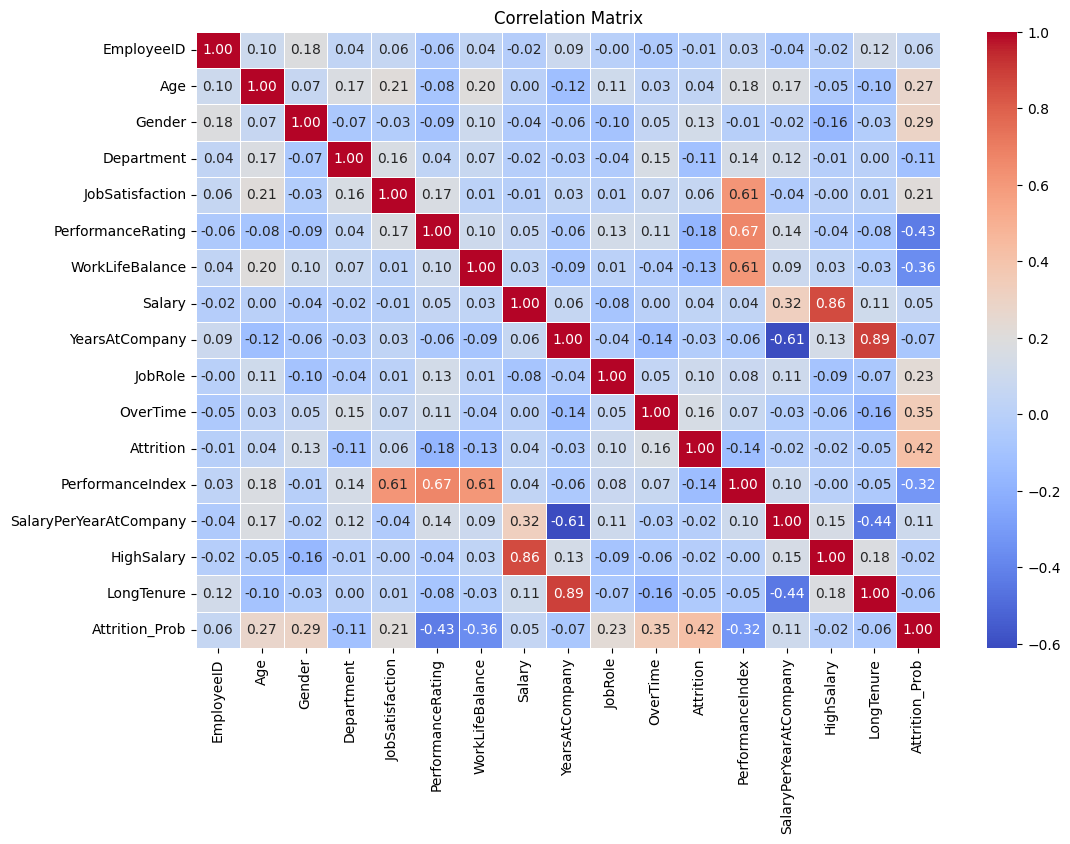

In [4]:

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

# Feature Engineering

In [5]:

df['PerformanceIndex'] = df['JobSatisfaction'] * df['WorkLifeBalance'] * df['PerformanceRating']

# Model Development for Attrition Prediction

In [6]:

X = df.drop(columns=['EmployeeID', 'Attrition'])
y = df['Attrition']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


logreg = LogisticRegression()
decision_tree = DecisionTreeClassifier(random_state=42)
random_forest = RandomForestClassifier(random_state=42)


logreg.fit(X_train, y_train)
decision_tree.fit(X_train, y_train)
random_forest.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

# Model Evaluation

Logistic Regression Accuracy: 0.4666666666666667
Decision Tree Accuracy: 0.6
Random Forest Accuracy: 0.6

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.53      0.53        17
           1       0.38      0.38      0.38        13

    accuracy                           0.47        30
   macro avg       0.46      0.46      0.46        30
weighted avg       0.47      0.47      0.47        30


Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.41      0.54        17
           1       0.52      0.85      0.65        13

    accuracy                           0.60        30
   macro avg       0.65      0.63      0.59        30
weighted avg       0.67      0.60      0.59        30


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.53      0.60        17
           1

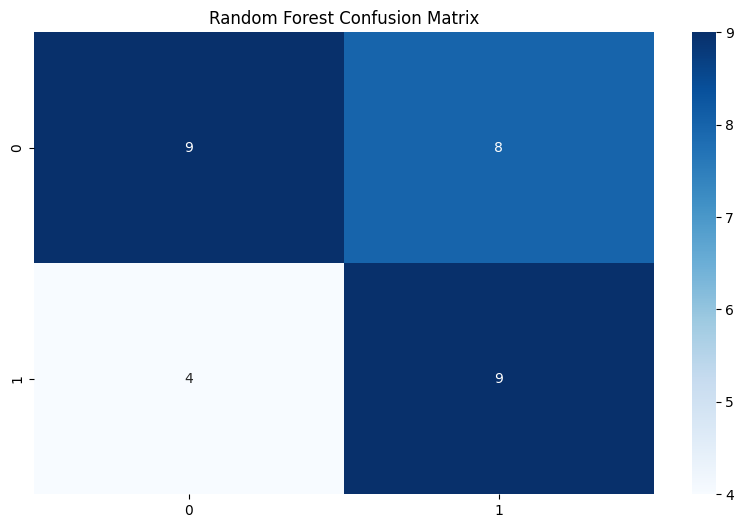

Random Forest Cross-Validation Scores: [0.55 0.55 0.75 0.6  0.7 ]
Average Cross-Validation Score: 0.6300000000000001


In [7]:

y_pred_logreg = logreg.predict(X_test)
y_pred_tree = decision_tree.predict(X_test)
y_pred_rf = random_forest.predict(X_test)


print('Logistic Regression Accuracy:', accuracy_score(y_test, y_pred_logreg))
print('Decision Tree Accuracy:', accuracy_score(y_test, y_pred_tree))
print('Random Forest Accuracy:', accuracy_score(y_test, y_pred_rf))


print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, y_pred_logreg))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_tree))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))


plt.figure(figsize=(10, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, cmap='Blues', fmt='d')
plt.title('Random Forest Confusion Matrix')
plt.show()


cv_scores_rf = cross_val_score(random_forest, X, y, cv=5)
print("Random Forest Cross-Validation Scores:", cv_scores_rf)
print("Average Cross-Validation Score:", np.mean(cv_scores_rf))

# Analysis of Job Satisfaction vs. Performance

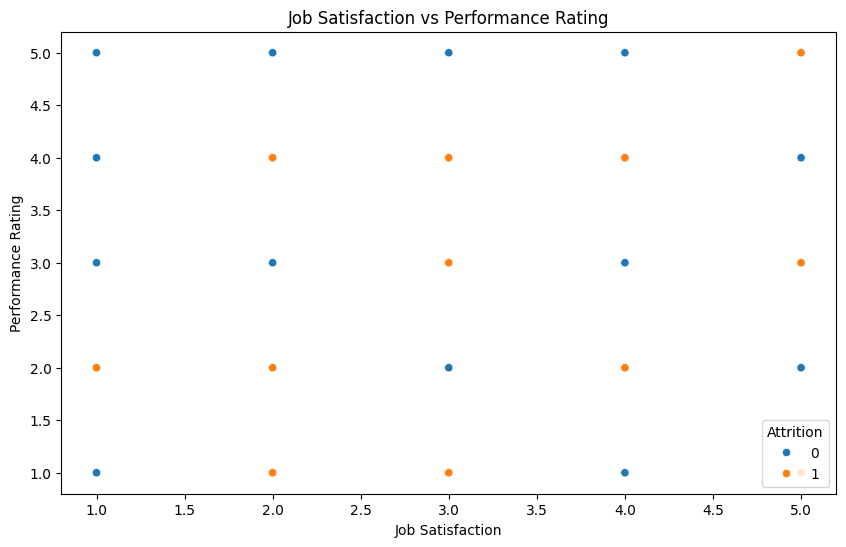

Correlation between Job Satisfaction and Performance Rating: 0.16636358710114857


In [8]:

plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['JobSatisfaction'], y=df['PerformanceRating'], hue=df['Attrition'])
plt.title('Job Satisfaction vs Performance Rating')
plt.xlabel('Job Satisfaction')
plt.ylabel('Performance Rating')
plt.show()


satisfaction_performance_corr = df[['JobSatisfaction', 'PerformanceRating']].corr()
print("Correlation between Job Satisfaction and Performance Rating:", satisfaction_performance_corr.iloc[0, 1])


# Overtime Analysis

In [9]:

overtime_performance = df.groupby('OverTime')['PerformanceRating'].mean()
print("\nAverage Performance Ratings for Overtime Employees vs Non-Overtime Employees:")
print(overtime_performance)


overtime_attrition = df.groupby('OverTime')['Attrition'].mean()
print("\nAttrition Rates for Overtime Employees vs Non-Overtime Employees:")
print(overtime_attrition)


Average Performance Ratings for Overtime Employees vs Non-Overtime Employees:
OverTime
0    2.886792
1    3.212766
Name: PerformanceRating, dtype: object

Attrition Rates for Overtime Employees vs Non-Overtime Employees:
OverTime
0    0.377358
1    0.531915
Name: Attrition, dtype: float64


# Departmental Attrition and Performance Analysis

In [10]:

department_attrition = df.groupby('Department')['Attrition'].mean()
department_performance = df.groupby('Department')['PerformanceRating'].mean()

print("\nDepartment-wise Attrition Rates:")
print(department_attrition)

print("\nDepartment-wise Average Performance Ratings:")
print(department_performance)


Department-wise Attrition Rates:
Department
0    0.444444
1    0.687500
2    0.347826
3    0.500000
4    0.200000
Name: Attrition, dtype: float64

Department-wise Average Performance Ratings:
Department
0    2.925926
1      2.6875
2    3.521739
3    3.041667
4         2.8
Name: PerformanceRating, dtype: object


#  Salary And Tenure Analysis


Attrition rate by Salary range:
Salary
(-1.661, -0.944]    0.315789
(-0.944, -0.232]    0.615385
(-0.232, 0.481]     0.263158
(0.481, 1.194]      0.590909
(1.194, 1.906]      0.357143
Name: Attrition, dtype: float64


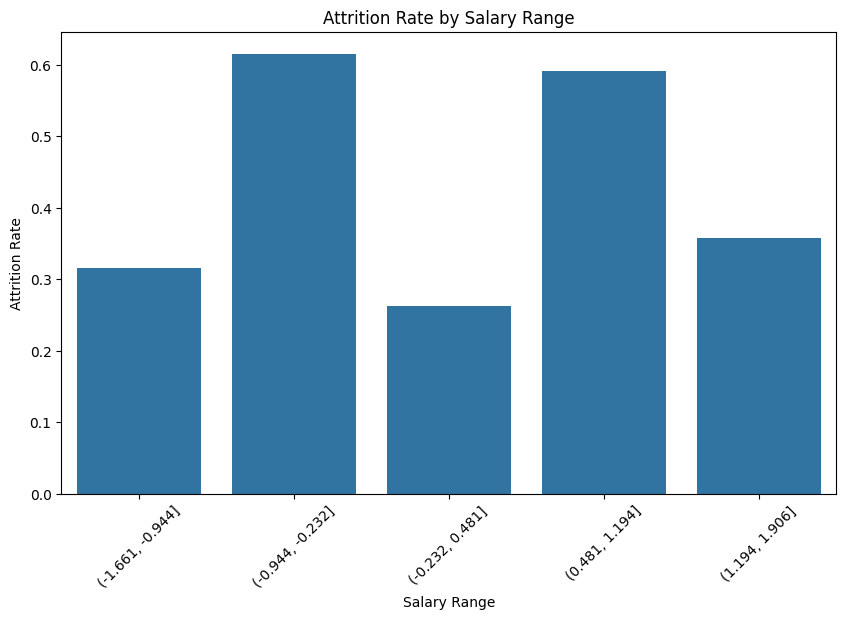


Attrition rate by Tenure range:
YearsAtCompany
(-1.523, -0.91]    0.545455
(-0.91, -0.3]      0.347826
(-0.3, 0.31]       0.384615
(0.31, 0.92]       0.588235
(0.92, 1.531]      0.400000
Name: Attrition, dtype: float64


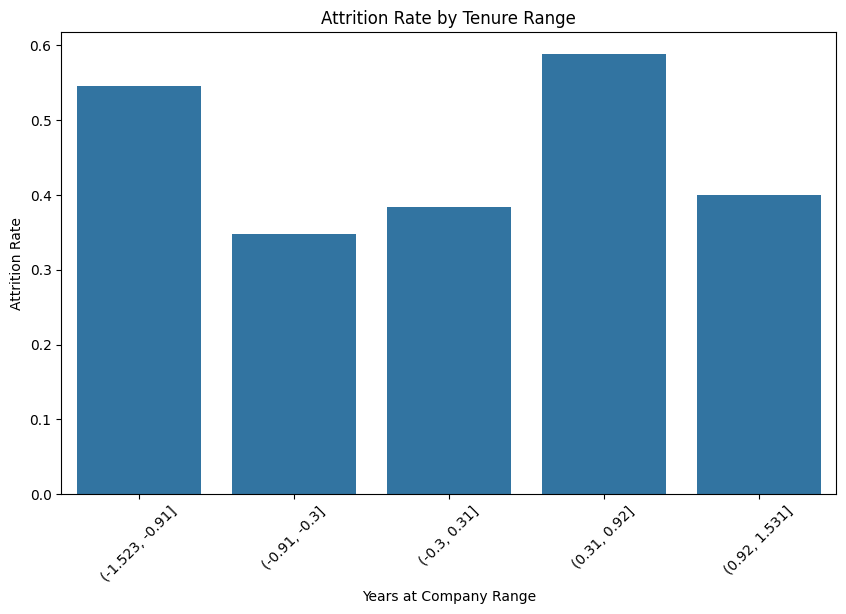

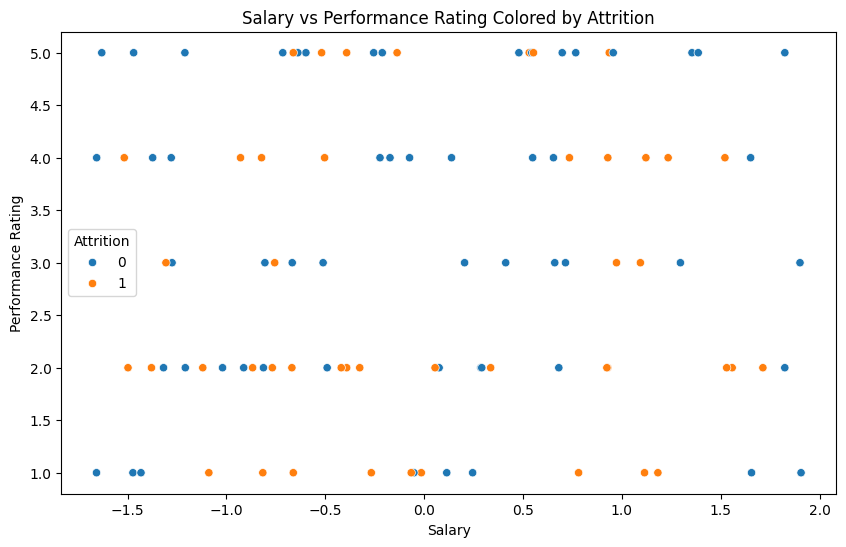

In [11]:

salary_bins = pd.cut(df['Salary'], bins=5)  
salary_attrition = df.groupby(salary_bins)['Attrition'].mean()
print("\nAttrition rate by Salary range:")
print(salary_attrition)

plt.figure(figsize=(10, 6))
sns.barplot(x=salary_attrition.index.astype(str), y=salary_attrition.values)
plt.xticks(rotation=45)
plt.title('Attrition Rate by Salary Range')
plt.xlabel('Salary Range')
plt.ylabel('Attrition Rate')
plt.show()

tenure_bins = pd.cut(df['YearsAtCompany'], bins=5)  
tenure_attrition = df.groupby(tenure_bins)['Attrition'].mean()
print("\nAttrition rate by Tenure range:")
print(tenure_attrition)

plt.figure(figsize=(10, 6))
sns.barplot(x=tenure_attrition.index.astype(str), y=tenure_attrition.values)
plt.xticks(rotation=45)
plt.title('Attrition Rate by Tenure Range')
plt.xlabel('Years at Company Range')
plt.ylabel('Attrition Rate')
plt.show()


plt.figure(figsize=(10, 6))
sns.scatterplot(x='Salary', y='PerformanceRating', hue='Attrition', data=df)
plt.title('Salary vs Performance Rating Colored by Attrition')
plt.xlabel('Salary')
plt.ylabel('Performance Rating')
plt.show()


# Thank you!